<a href="https://colab.research.google.com/github/ashrithpatha/ASML_Project_and_Labs/blob/main/STP_Lab_2_Module_3_Implementing_KNN_from_scratch_and_visualize_Algorithm_performance_by_Om_Kathalkar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Student Training Program on AIML**
### MODULE 3: CLASSIFICATION-1
### LAB-2 : Implementing KNN from scratch and visualize Algorithm performance

---

# **Section 1: Implementing KNN**

In the last lab we had started discussing about KNN or K Nearest Neighbour method for clasification. We used the pre-built scikit-learn library for KNN. Now let's see how to implement this algorithm from scratch  

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn import preprocessing
from collections import Counter

In [2]:
def predict(X_train, y_train, X_test, k):

    distances = []

    for i in range(len(X_train)):

        # Euclidean distance
        dist = np.sqrt(np.sum((X_test - X_train[i, :]) ** 2))

        distances.append((dist, y_train[i]))

    # Sort by distance
    distances.sort(key=lambda x: x[0])

    # Get nearest k neighbors
    neighbors = [label for _, label in distances[:k]]

    # Majority vote
    prediction = Counter(neighbors).most_common(1)[0][0]

    return prediction

In [3]:
def k_nearest_neighbor(X_train, y_train, X_test, k):
    assert k <= len(X_train), "[!] K cannot be larger than number of samples."
    predictions = []
    # Loop through test samples
    for test_point in X_test:

        prediction = predict(
            X_train,
            y_train,
            test_point,
            k
        )
        predictions.append(prediction)

    return np.array(predictions)

**Note** : If k = 1 then the algorithm will simply return the label of the nearest neighbour. When we give k > 1 the most common label out of the given labels in the k neighbours will be selected.The code for 1 NN is given as follows and does not have to be so complicated.

In [4]:
def NN1(traindata, trainlabel, query):

    diff = traindata - query
    sq = diff ** 2
    dist = sq.sum(axis=1)

    label = trainlabel[np.argmin(dist)]

    return label

Let us define a metric 'Accuracy' to see how good our learning algorithm is. Accuracy is the ratio of the number of correctly classified samples to the total number of samples. The higher the accuracy, the better the algorithm.

In [5]:
def Accuracy(gtlabel, predlabel):

    assert len(gtlabel) == len(predlabel), \
        "Length of ground truth and predicted labels must be the same"
    correct = (gtlabel == predlabel).sum()

    accuracy = correct / len(gtlabel)

    return accuracy

## Section 1.1 - Iris Dataset
Let's try it out on Iris Dataset present in the scikit learn library

In [6]:
from sklearn.datasets import load_iris

data = load_iris()

df = pd.DataFrame(data=data.data, columns=data.feature_names)

df["target"] = data.target

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [7]:
X = np.array(df[['sepal length (cm)','sepal width (cm)','petal length (cm)','petal width (cm)']])
y = np.array(df['target'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=17)

In [8]:
predictions = k_nearest_neighbor(
    X_train,
    y_train,
    X_test,
    5
)
accuracy = Accuracy(y_test, predictions)

print(
    "The accuracy of our classifier is {} %".format(
        100 * accuracy
    )
)

The accuracy of our classifier is 96.0 %


Voila! You have implemented your own version of the K-Nearest Neighbours algorithm, which works very well on the Iris Dataset. Congratulations!  

Now try out the sklearn implementation and compare your results.  

In [9]:
from sklearn.neighbors import KNeighborsClassifier
sklearn_knn = KNeighborsClassifier(
    n_neighbors=5
)

# Train model
sklearn_knn.fit(X_train, y_train)

# Predictions
sklearn_predictions = sklearn_knn.predict(X_test)
# Accuracy
accuracy = accuracy_score(
    y_test,
    sklearn_predictions
)
print(
    "The accuracy of Sklearn classifier is {} %".format(
        100 * accuracy
    )
)

The accuracy of Sklearn classifier is 96.0 %


##  Section 1.2: Weighted NN
For KNN, If k is too small, the algorithm would be more sensitive to outliers. If k is too large, then the neighborhood may include too many points from other classes. We also take the label with max votes in the neighbourhood. Another choice can be that instead of giving equal weights to each of the neighbours we can give weighted points in the neighbourhood. So we weigh points by the inverse of their distance. Therefore, closer points will be given a higher priority as compared to the far off points.

An easy way to implement this is by specifying the 'weights' parameter as distance when defining the sklearn KNN function. For more information go through this [site](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)

In [10]:
def predict_neighbors(X_train, y_train, X_test, k):

    distances = []

    # Calculate distances
    for i in range(len(X_train)):

        dist = np.sqrt(
            np.sum((X_test - X_train[i, :]) ** 2)
        )

        distances.append(
            (dist, y_train[i])
        )

    # Sort by distance
    distances.sort(key=lambda x: x[0])

    # Return k nearest neighbors
    neighbors = distances[:k]

    return neighbors

In [12]:
neighbors = predict_neighbors(
    X_train,
    y_train,
    X_test[0],
    5
)

print(neighbors)

[(np.float64(0.3464101615137753), np.int64(0)), (np.float64(0.3872983346207418), np.int64(0)), (np.float64(0.41231056256176646), np.int64(0)), (np.float64(0.4582575694955838), np.int64(0)), (np.float64(0.45825756949558394), np.int64(0))]


# **Section 2: Visualizing Data**  

We will look into something called **Voronoi** diagrams.  

**Note**: Ideally, we should perform data visualization to see what the data looks like before we apply any Machine Learning algorithm.  Only for the purpose of this lab session, we're explaining it after you've applied KNN.

### Voronoi Diagrams  

In simple terms, Voronoi diagrams help you to visualize the dataset by partioning the plane into regions that are close to a given set of points. These regions are also called Voronoi cells.  

Note that the cells/regions depend on the Distance metric being used. One way of interpreting this is by understanding that the distance metric decides the degree to which a 'point' or 'seed' in the Voronoi diagram has influence.  For each seed there is a corresponding region, called a Voronoi cell, consisting of all points of the plane closer to that seed than to any other.

This [link](https://en.wikipedia.org/wiki/Voronoi_diagram#Illustration) provides a wonderful illustration of Voronoi plots for 20 points in two cases: (1) Using Euclidean distance, and (2) Using Manhattan distance.  



Since our Iris data is 4-dimensional (as it has 4 attributes), we need to convert into a form that can be represented in 2-D.   

While there are methods to visualize data higher than 2-dimensions, that is beyond scope for now.  

For simplicity, we just take the first two columns of the iris dataset attributes and observe the Voronoi diagram generated for that.  
Alternatively, one can also perform PCA (Principal Component Analysis), to reduce the 4D data to just two dimensions.

In [13]:
#@title Plotting Voronoi regions
import matplotlib.pyplot as plt
from scipy.spatial import Voronoi, voronoi_plot_2d

def voronoi_finite_polygons_2d(vor, radius=None):
    """
    Reconstruct infinite voronoi regions in a 2D diagram to finite
    regions.

    Parameters
    ----------
    vor : Voronoi
        Input diagram
    radius : float, optional
        Distance to 'points at infinity'.

    Returns
    -------
    regions : list of tuples
        Indices of vertices in each revised Voronoi regions.
    vertices : list of tuples
        Coordinates for revised Voronoi vertices. Same as coordinates
        of input vertices, with 'points at infinity' appended to the
        end.

    """

    if vor.points.shape[1] != 2:
        raise ValueError("Requires 2D input")

    new_regions = []
    new_vertices = vor.vertices.tolist()

    center = vor.points.mean(axis=0)
    if radius is None:
        radius = np.ptp(vor.points, axis=0).max()

    # Construct a map containing all ridges for a given point
    all_ridges = {}
    for (p1, p2), (v1, v2) in zip(vor.ridge_points, vor.ridge_vertices):
        all_ridges.setdefault(p1, []).append((p2, v1, v2))
        all_ridges.setdefault(p2, []).append((p1, v1, v2))

    # Reconstruct infinite regions
    for p1, region in enumerate(vor.point_region):
        vertices = vor.regions[region]

        if all(v >= 0 for v in vertices):
            # finite region
            new_regions.append(vertices)
            continue

        # reconstruct a non-finite region
        ridges = all_ridges[p1]
        new_region = [v for v in vertices if v >= 0]

        for p2, v1, v2 in ridges:
            if v2 < 0:
                v1, v2 = v2, v1
            if v1 >= 0:
                # finite ridge: already in the region
                continue

            # Compute the missing endpoint of an infinite ridge

            t = vor.points[p2] - vor.points[p1] # tangent
            t /= np.linalg.norm(t)
            n = np.array([-t[1], t[0]])  # normal

            midpoint = vor.points[[p1, p2]].mean(axis=0)
            direction = np.sign(np.dot(midpoint - center, n)) * n
            far_point = vor.vertices[v2] + direction * radius

            new_region.append(len(new_vertices))
            new_vertices.append(far_point.tolist())

        # sort region counterclockwise
        vs = np.asarray([new_vertices[v] for v in new_region])
        c = vs.mean(axis=0)
        angles = np.arctan2(vs[:,1] - c[1], vs[:,0] - c[0])
        new_region = np.array(new_region)[np.argsort(angles)]

        # finish
        new_regions.append(new_region.tolist())

    return new_regions, np.asarray(new_vertices)

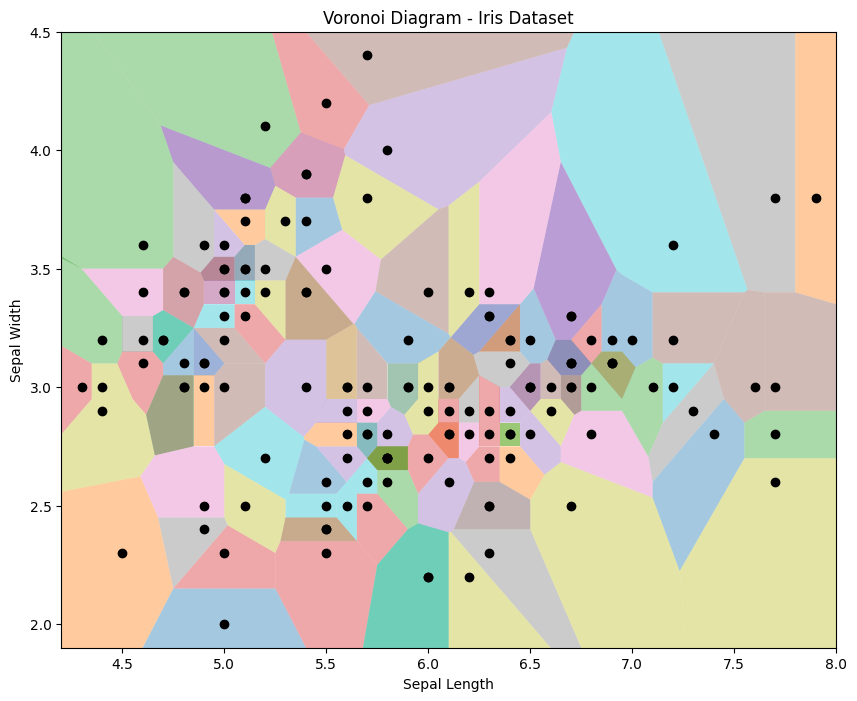

In [14]:
## Plotting Voronoi regions for the Iris dataset

points = []

xpts = np.array(df['sepal length (cm)'])
ypts = np.array(df['sepal width (cm)'])

for i in range(len(xpts)):
    points.append([xpts[i], ypts[i]])

points = np.array(points)

# Compute Voronoi tessellation
vor = Voronoi(points)

regions, vertices = voronoi_finite_polygons_2d(vor)
plt.figure(figsize=(10, 8))

for region in regions:

    polygon = vertices[region]

    plt.fill(*zip(*polygon), alpha=0.4)

# Plot original points
plt.plot(points[:, 0], points[:, 1], 'ko')

plt.xlim(vor.min_bound[0] - 0.1, vor.max_bound[0] + 0.1)
plt.ylim(vor.min_bound[1] - 0.1, vor.max_bound[1] + 0.1)
plt.title("Voronoi Diagram - Iris Dataset")
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.show()

## Section 2.2: Understanding Decision Boundaries  
So you have seen the Voronoi diagram of the dataset, implemented KNN, and also seen your algorithm's performance in terms of accuracy? Impressive!  
Wouldn't it also be great to know how exactly these 'votes' or neighbours are decided through some kind of visualization?  


### Decision Boundary

While the Voronoi diagram gave us a good idea of the points present in our dataset, to understand how KNN performed on our dataset we can plot decision boundaries. Decision boundaries, as the name suggests, divide the plane into different regions of classification.  

Note that here again, for simplicity, we have only considered first two attributes of the DataFrame (ie, Sepal Length and Sepal Width).  

In [15]:
from matplotlib.colors import ListedColormap
import seaborn as sns
def decision_boundary_plot(x_dec, y_dec, k):
    h = .02  # step size in mesh
    n = len(set(y_dec))
    cmap_light = ListedColormap(
        ['pink', 'green', 'cyan', 'yellow'][:n]
    )
    cmap_bold = [
        'pink',
        'darkgreen',
        'blue',
        'yellow'
    ][:n]
    for weights in ['uniform', 'distance']:
        clf = KNeighborsClassifier(
            n_neighbors=k,
            weights=weights
        )
        clf.fit(x_dec, y_dec)
        x_min, x_max = (
            x_dec[:, 0].min() - 1,
            x_dec[:, 0].max() + 1
        )
        y_min, y_max = (
            x_dec[:, 1].min() - 1,
            x_dec[:, 1].max() + 1
        )

        xx, yy = np.meshgrid(
            np.arange(x_min, x_max, h),
            np.arange(y_min, y_max, h)
        )

        # Predictions
        Z = clf.predict(
            np.c_[xx.ravel(), yy.ravel()]
        )
        Z = Z.reshape(xx.shape)
        # Plot
        plt.figure(figsize=(10, 7))
        plt.contourf(xx, yy, Z, cmap=cmap_light)
        sns.scatterplot(
            x=x_dec[:, 0],
            y=x_dec[:, 1],
            hue=y_dec,
            palette=cmap_bold,
            alpha=0.9,
            edgecolor="black"
        )

        plt.xlim(xx.min(), xx.max())
        plt.ylim(yy.min(), yy.max())
        plt.xlabel("Sepal Length")
        plt.ylabel("Sepal Width")
        plt.title(
            "Multi-Classification (k = %i, weights = '%s')"
            % (k, weights)
        )

    plt.show()

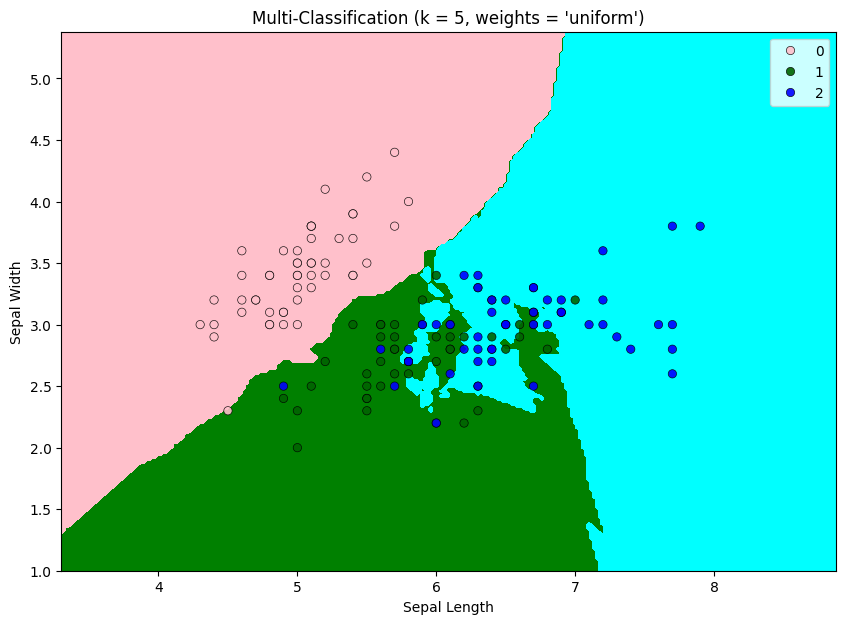

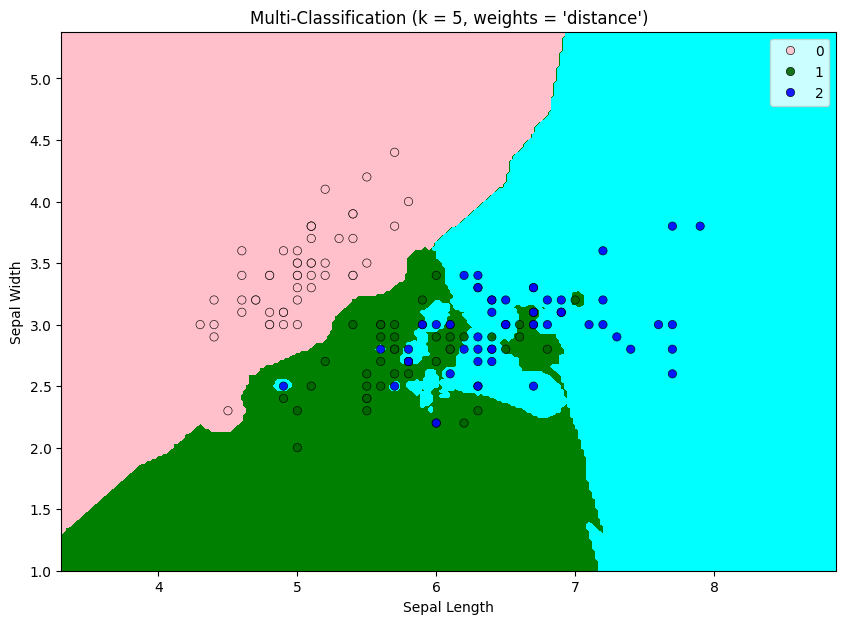

In [16]:
x_pts = X[:, :2]
y_pts = y
decision_boundary_plot(
    x_pts,
    y_pts,
    5
)

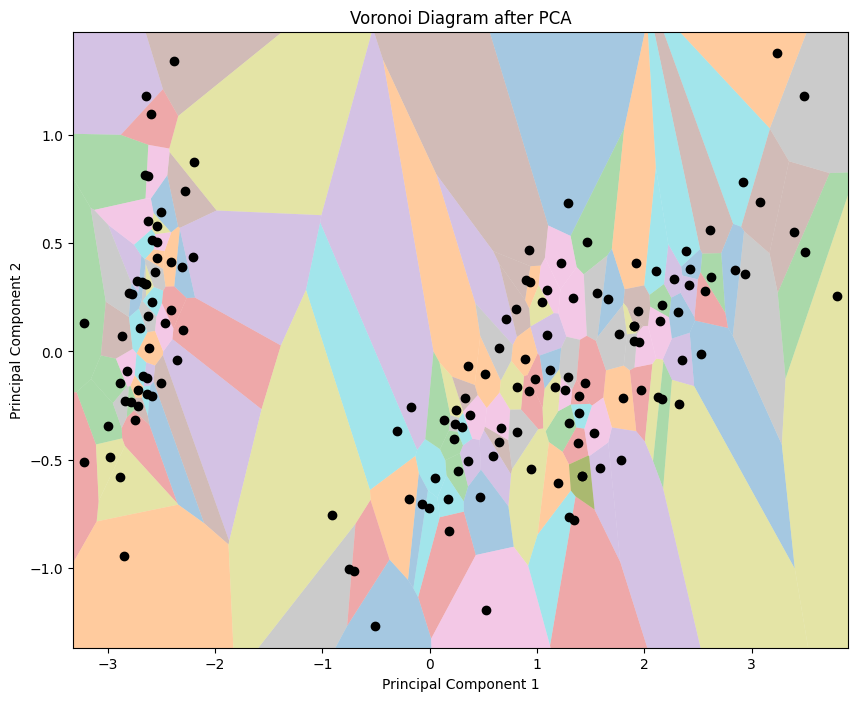

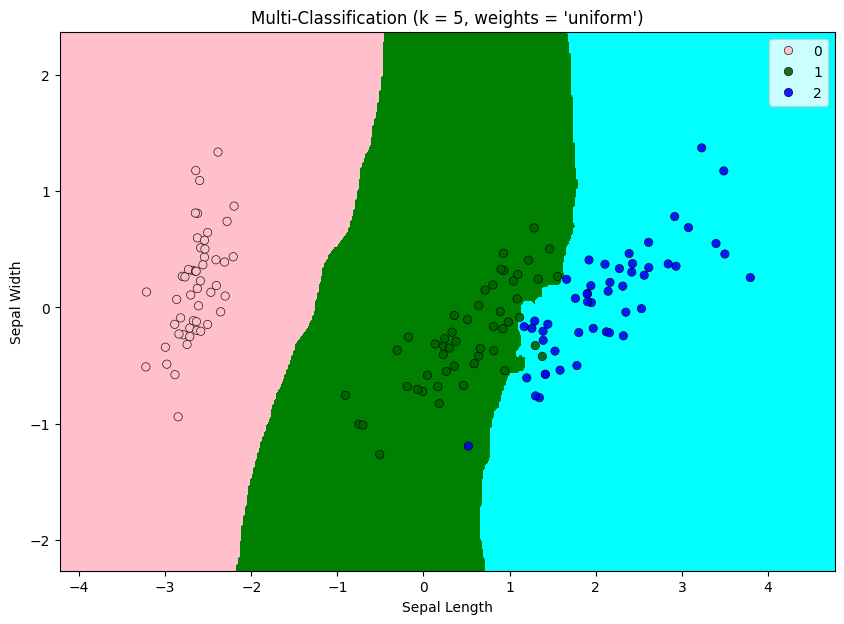

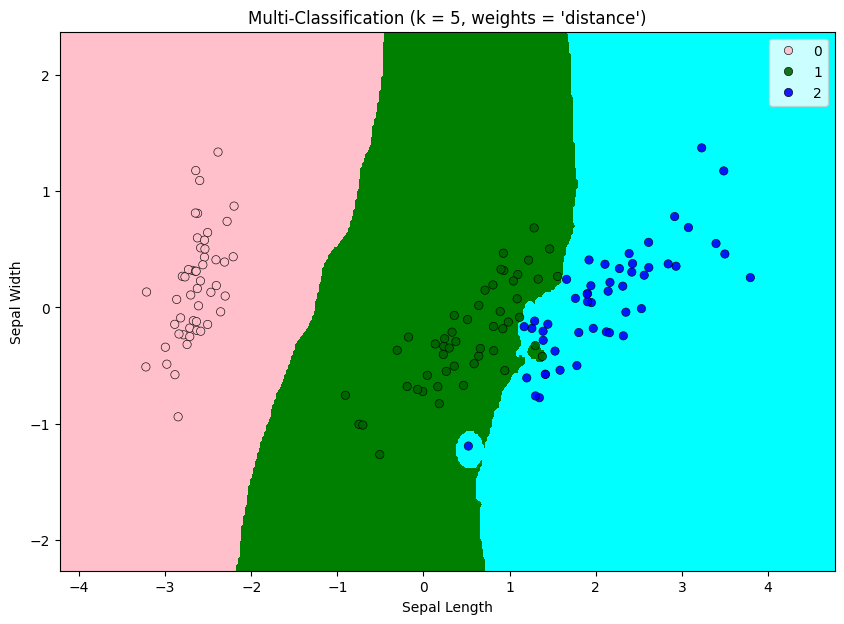

In [17]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

# Separate transformed points
xpts = X_pca[:, 0]
ypts = X_pca[:, 1]

# Create points array
points = np.column_stack((xpts, ypts))

# Compute Voronoi tessellation
vor = Voronoi(points)
regions, vertices = voronoi_finite_polygons_2d(vor)
# Plot Voronoi Diagram
plt.figure(figsize=(10, 8))
for region in regions:
    polygon = vertices[region]
    plt.fill(*zip(*polygon), alpha=0.4)
# Plot PCA points
plt.plot(points[:, 0], points[:, 1], 'ko')
plt.xlim(vor.min_bound[0] - 0.1,
         vor.max_bound[0] + 0.1)
plt.ylim(vor.min_bound[1] - 0.1,
         vor.max_bound[1] + 0.1)
plt.title("Voronoi Diagram after PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()
decision_boundary_plot(X_pca, y, 5)

## Section 2.3: Confusion Matrix  
In classification problems, a confusion matrix, also known as an error matrix, is a table that allows visualization of the performance of an algorithm, typically a supervised learning one. Each row of the matrix represents the instances in an actual class while each column represents the instances in a predicted class.

In [18]:
from sklearn.metrics import confusion_matrix

In [19]:
# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    predictions
)

# Print confusion matrix
print("Confusion Matrix:\n")

print(cm)

print("\nDetailed Crosstab:\n")

# Crosstab representation
pd.crosstab(
    y_test,
    predictions,
    rownames=['True'],
    colnames=['Predicted'],
    margins=True
)

Confusion Matrix:

[[13  0  0]
 [ 0 22  0]
 [ 0  2 13]]

Detailed Crosstab:



Predicted,0,1,2,All
True,,,,
0,13,0,0,13
1,0,22,0,22
2,0,2,13,15
All,13,24,13,50


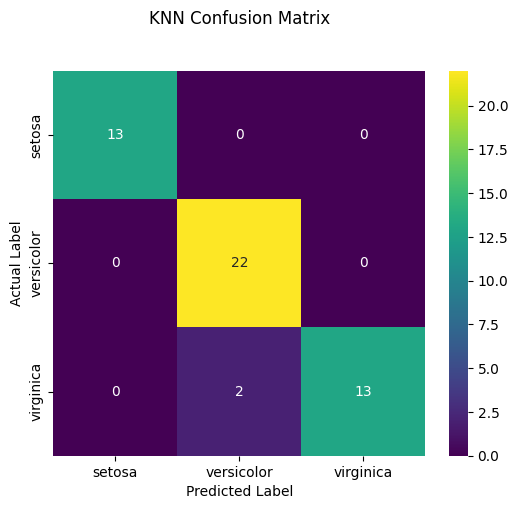

In [20]:
from sklearn import metrics
# Generate confusion matrix
cnf_matrix = metrics.confusion_matrix(
    y_test,
    predictions
)
plt.figure(figsize=(6, 5))
# Heatmap
sns.heatmap(
    pd.DataFrame(cnf_matrix),
    annot=True,
    cmap="viridis",
    fmt='g',
    xticklabels=data.target_names,
    yticklabels=data.target_names
)
# Labels and title
plt.title(
    'KNN Confusion Matrix',
    y=1.1
)
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

## Section 2.4: Classification Report

Precision, Recall, and F1-Score are other metrics besides accuracy that one might look for in an algorithm.  Depending on the use-case, one might consider one metric more important than the other.  

Note: *T-> True, F->False, P->Positive, N->Negative*
    
Mathematically, Accuracy is :  

$Accuracy = \frac{TP+TN}{TP+TN+FP+FN}$  

**Precision**: The accuracy of positive predictions


$Precision = \frac{TP}{TP+FP}$

**Recall**:Fraction of positives that were correctly identified


$Recall = \frac{TP}{TP+FN}$


**F1-score**: Harmonic mean of precision and recall  


$F1 = \frac{2*Precision*Recall}{Precision+Recall} = \frac{2*TP}{2*TP+FP+FN}$  



In [21]:
from sklearn.metrics import classification_report
print("Classification Report:\n")
print(
    classification_report(
        y_test,
        predictions,
        target_names=data.target_names
    )
)

Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        13
  versicolor       0.92      1.00      0.96        22
   virginica       1.00      0.87      0.93        15

    accuracy                           0.96        50
   macro avg       0.97      0.96      0.96        50
weighted avg       0.96      0.96      0.96        50



### **Car Evaluation Dataset**

In [ ]:
# Upload the Car evaluation data CSV file that has been shared with you.
# Run this cell, click on the 'Choose files' button and upload the file.
from google.colab import files
uploaded = files.upload()

In [ ]:
car_df = pd.read_csv(list(uploaded.keys())[0])
car_df

In [ ]:
for column in car_df.columns:
    le = preprocessing.LabelEncoder()

    car_df[column] = le.fit_transform(
        car_df[column]
    )
car_df

In [ ]:
dataset = car_df.values
X = dataset[:,0:6]
y = np.array(dataset[:,6])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=19)

In [ ]:
knn = KNeighborsClassifier(
    n_neighbors=7
)
knn.fit(X_train, y_train)
predictions = knn.predict(X_test)
score = accuracy_score(
    y_test,
    predictions
)
print(
    "The accuracy of the classifier on Car evaluation dataset is {:.2f} %".format(
        100 * score
    )
)

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    predictions
)
# Plot heatmap
plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='g',
    cmap='viridis'
)
# Labels and title
plt.title("Confusion Matrix - Car Evaluation Dataset")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [ ]:
from sklearn.metrics import classification_report
# Print classification report
print("Classification Report:\n")
print(
    classification_report(
        y_test,
        predictions
    )
)

In [ ]:
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap
import seaborn as sns
import matplotlib.pyplot as plt
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
# Train-test split on PCA data
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca,
    y,
    test_size=0.2,
    random_state=19
)
# Train KNN classifier
knn = KNeighborsClassifier(
    n_neighbors=5
)
knn.fit(X_train_pca, y_train_pca)
# Create mesh grid
h = 0.02
x_min, x_max = (
    X_pca[:, 0].min() - 1,
    X_pca[:, 0].max() + 1
)
y_min, y_max = (
    X_pca[:, 1].min() - 1,
    X_pca[:, 1].max() + 1
)
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, h),
    np.arange(y_min, y_max, h)
)
# Predict regions
Z = knn.predict(
    np.c_[xx.ravel(), yy.ravel()]
)
Z = Z.reshape(xx.shape)
# Plot decision boundary
plt.figure(figsize=(10, 7))
cmap_light = ListedColormap(
    ['pink', 'lightgreen', 'lightblue', 'yellow']
)
plt.contourf(
    xx,
    yy,
    Z,
    cmap=cmap_light,
    alpha=0.6
)
# Plot points
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=y,
    palette='deep',
    edgecolor='black'
)
plt.title(
    "Decision Boundary - Car Evaluation Dataset"
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In [ ]:
from sklearn.decomposition import PCA
from scipy.spatial import Voronoi, voronoi_plot_2d
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

# Create Voronoi object
vor = Voronoi(X_pca)

# Plot Voronoi diagram directly
plt.figure(figsize=(10, 8))

voronoi_plot_2d(
    vor,
    show_vertices=False,
    line_colors='black',
    line_width=1,
    line_alpha=0.6,
    point_size=3
)

# Plot original points
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap='viridis',
    edgecolors='black'
)

plt.title(
    "Voronoi Diagram - Car Evaluation Dataset"
)

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.show()

## **Homework Assignment: Exploring Distance Metrics and KNN**

---

### **Problem 1: Implementing Custom Distance Metrics**

In this exercise, you'll implement distance metrics from scratch to deepen your understanding.

**Task 1.1:** Implement the Minkowski distance formula without using any library functions (except basic numpy operations).

Recall that Minkowski distance is defined as:

$$d(x, x') = \left(\sum_{j=1}^{D} |x_j - x'_j|^p\right)^{1/p}$$

where $p$ is a parameter. When $p=1$, it's Manhattan distance, and when $p=2$, it's Euclidean distance.

In [ ]:
from scipy.spatial import distance

In [ ]:
from scipy.spatial import distance

## HOMEWORK TASK 1.1

def minkowski_distance(x1, x2, p):

    distance_value = np.sum(
        np.abs(x1 - x2) ** p
    ) ** (1 / p)

    return distance_value


# Test your implementation
x_1 = np.array([1, 2, 3])

x_2 = np.array([4, 6, 8])

# Test with p=1
print(
    "Minkowski distance (p=1):",
    minkowski_distance(x_1, x_2, 1)
)

print(
    "Manhattan distance:",
    distance.cityblock(x_1, x_2)
)

print()

# Test with p=2
print(
    "Minkowski distance (p=2):",
    minkowski_distance(x_1, x_2, 2)
)

print(
    "Euclidean distance:",
    distance.euclidean(x_1, x_2)
)

---

### **Problem 2: Visualizing Decision Boundaries**

Understanding how KNN makes predictions is crucial. In this exercise, you'll visualize decision boundaries for different values of K.

**Task 2.1:** Create a function that visualizes the decision boundary of a KNN classifier on 2D data.

**Hint:** You'll need to:
1. Create a mesh grid covering the feature space
2. Train a KNN classifier
3. Predict the class for each point in the mesh
4. Plot the results using `plt.contourf()` for the decision boundary
5. Overlay the training data points

In [ ]:
from sklearn.datasets import make_blobs
# Generate synthetic dataset
def generate_synth_data(n):
    X, y = make_blobs(
        n_samples=n,
        centers=2,
        n_features=2,
        random_state=42,
        cluster_std=2.0
    )

    return X, y

In [ ]:
## HOMEWORK TASK 2.1

def plot_decision_boundary(X, y, k_value, metric='euclidean'):

    """
    Plot the decision boundary for KNN classifier.
    """

    # Create mesh grid
    h = 0.02

    x_min, x_max = (
        X[:, 0].min() - 1,
        X[:, 0].max() + 1
    )

    y_min, y_max = (
        X[:, 1].min() - 1,
        X[:, 1].max() + 1
    )

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, h),
        np.arange(y_min, y_max, h)
    )

    # Train KNN classifier
    knn = KNeighborsClassifier(
        n_neighbors=k_value,
        metric=metric
    )

    knn.fit(X, y)

    # Predict mesh points
    Z = knn.predict(
        np.c_[xx.ravel(), yy.ravel()]
    )

    Z = Z.reshape(xx.shape)

    # Plot decision boundary
    plt.figure(figsize=(10, 6))

    plt.contourf(
        xx,
        yy,
        Z,
        alpha=0.4,
        cmap='coolwarm'
    )

    # Plot training points
    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        edgecolor='black',
        cmap='coolwarm'
    )

    plt.xlabel('Feature 1')

    plt.ylabel('Feature 2')

    plt.title(
        f'KNN Decision Boundary (k={k_value}, metric={metric})'
    )

    plt.show()


# Generate synthetic data
n = 50

pts, tgts = generate_synth_data(n)

# Test different k values
for k in [1, 3, 5, 10]:

    plot_decision_boundary(
        pts,
        tgts,
        k
    )

**Discussion Questions:**
1. What happens to the decision boundary as K increases? Is it smoother or more irregular?

Answer:
As the value of K increases, the decision boundary becomes smoother and less complex. Smaller K values create irregular and highly detailed boundaries because the classifier becomes more sensitive to individual data points and noise.


2. Which K value seems to generalize better without overfitting?

Answer:
Moderate K values such as 5 or 7 usually provide better generalization. Very small K values may overfit the training data, while very large K values can oversimplify the decision boundary and lead to underfitting.

3. Try changing the metric to 'manhattan' - how does the boundary change?

Answer:
When the distance metric is changed to Manhattan distance, the decision boundaries become slightly more axis-aligned and block-shaped compared to Euclidean distance. This happens because Manhattan distance measures movement along horizontal and vertical directions instead of straight-line distance.

---

### **Problem 3: Impact of Distance Metrics on High-Dimensional Data**

The "curse of dimensionality" affects distance metrics differently. Let's explore this phenomenon.

**Task 3.1:** Create a function that generates random high-dimensional data and compares how different distance metrics behave as dimensionality increases.

**Background:** In high dimensions, the ratio between the maximum and minimum distances between points tends to approach 1, making it harder to distinguish between near and far neighbors. This affects different metrics differently.

In [ ]:
## HOMEWORK TASK 3.1

def analyze_distance_in_high_dims(max_dim=50, n_points=100):

    """
    Analyze how distance metrics behave in high dimensions.
    """

    dimensions = range(2, max_dim + 1, 5)

    results = {
        'euclidean': [],
        'manhattan': [],
        'chebyshev': []
    }

    for dim in dimensions:

        # Generate random points
        points = np.random.randn(
            n_points,
            dim
        )

        # Euclidean distances
        euclidean_distances = distance.pdist(
            points,
            metric='euclidean'
        )

        # Manhattan distances
        manhattan_distances = distance.pdist(
            points,
            metric='cityblock'
        )

        # Chebyshev distances
        chebyshev_distances = distance.pdist(
            points,
            metric='chebyshev'
        )

        # Store ratios
        results['euclidean'].append(
            euclidean_distances.max() /
            euclidean_distances.min()
        )

        results['manhattan'].append(
            manhattan_distances.max() /
            manhattan_distances.min()
        )

        results['chebyshev'].append(
            chebyshev_distances.max() /
            chebyshev_distances.min()
        )

    # Plot results
    plt.figure(figsize=(12, 6))

    plt.plot(
        dimensions,
        results['euclidean'],
        marker='o',
        label='Euclidean'
    )

    plt.plot(
        dimensions,
        results['manhattan'],
        marker='s',
        label='Manhattan'
    )

    plt.plot(
        dimensions,
        results['chebyshev'],
        marker='^',
        label='Chebyshev'
    )

    plt.xlabel("Dimensions")

    plt.ylabel("Max Distance / Min Distance")

    plt.title(
        "Effect of High Dimensions on Distance Metrics"
    )

    plt.legend()

    plt.grid(True)

    plt.show()

    return results


# Run analysis
results = analyze_distance_in_high_dims()

### Questions to Think About and Answer
1. In the section on Decision boundaries, you must have seen that we ran the KNN algorithm twice: first with the _weights_ set to 'uniform' and then set to 'distance'. Find out the difference between these two.  

Answer:

When weights='uniform' is used, all nearest neighbors contribute equally to the prediction, regardless of how far they are from the query point. Each neighbor gets the same voting importance.

When weights='distance' is used, closer neighbors are given higher importance while farther neighbors contribute less. This often improves prediction accuracy because nearby points usually represent the query point more reliably.

2. What do you think could be the drawbacks of using KNN ?

Answer:

One major drawback of KNN is that it becomes computationally expensive for large datasets because distances must be calculated between the query point and all training samples.

KNN is also sensitive to noise and outliers, especially when the value of K is very small.

Another limitation is the curse of dimensionality, where distance metrics become less effective as the number of features increases.

Additionally, KNN requires proper feature scaling because features with larger ranges can dominate the distance calculations.

### Useful Resources for further reading
1. Interactive KNN visualization, with class boundaries: http://vision.stanford.edu/teaching/cs231n-demos/knn/  
